# Tutorial: El Perceptrón con Python y scikit-learn

**Técnica:** Perceptrón de Rosenblatt, un clasificador binario lineal supervisado.

**Contenido**
1. Fundamentos teóricos del Perceptrón
2. Modelo matemático y analítico
3. Pipeline de Machine Learning, etapa por etapa
   - 3.1 Recolección de datos (importar un CSV)
   - 3.2 Descripción y análisis del dataset
   - 3.3 Scatter plot
   - 3.4 Preparación de los datos (selección, train/test y escalado)
   - 3.5 Entrenamiento del modelo con scikit-learn
   - 3.6 Verificación: Perceptrón programado desde cero
   - 3.7 Evaluación (métricas)
   - 3.8 Visualización de la frontera de decisión
   - 3.9 Predicción con datos nuevos
   - 3.10 Limitaciones del Perceptrón
4. Conclusiones

> Cómo usarlo: ejecuta las celdas **en orden**, de arriba hacia abajo. Funciona igual en Google Colab y en Jupyter.

## 1. Fundamentos teóricos del Perceptrón

### 1.1 Origen
El Perceptrón fue propuesto por **Frank Rosenblatt** en 1957-1958, inspirado en cómo una neurona biológica recibe señales, las combina y "decide" si se activa. Es la unidad básica de las redes neuronales artificiales y uno de los primeros algoritmos de aprendizaje automático.

### 1.2 La neurona artificial
Un perceptrón funciona en tres pasos:
1. **Recibe entradas** $x_1, x_2, \dots, x_d$ (las características o *features* del dato).
2. **Las pondera:** cada entrada tiene un peso $w_j$ que indica qué tan importante es. Además hay un **sesgo** $b$ (*bias*) que desplaza el umbral de decisión.
3. **Decide:** suma todo y aplica una **función de activación escalón**: si la suma es suficientemente grande, la salida es la clase 1; si no, es la clase 0.

### 1.3 ¿Qué tipo de problema resuelve?
- Es un algoritmo de **aprendizaje supervisado** (necesita ejemplos con su etiqueta correcta).
- Es un **clasificador binario** (dos clases, por ejemplo 0 y 1).
- Es un **clasificador lineal**: separa las clases con una **recta** (en 2 dimensiones), un **plano** (en 3) o un **hiperplano** (en más dimensiones).

### 1.4 Separabilidad lineal y convergencia
Dos clases son **linealmente separables** si existe un hiperplano que deja todos los puntos de una clase de un lado y todos los de la otra del lado contrario.

**Teorema de convergencia del perceptrón:** si los datos son linealmente separables, el algoritmo encuentra un hiperplano separador en un número **finito** de correcciones.

### 1.5 Aprendizaje guiado por el error
El Perceptrón aprende **equivocándose**: recorre los datos uno por uno y **solo modifica sus pesos cuando clasifica mal** un ejemplo. Si acierta, no cambia nada. Cada pasada completa por los datos se llama **época**.

### 1.6 Limitaciones
- Si los datos **no** son linealmente separables, no converge: sigue corrigiendo sin llegar nunca a cero errores.
- No puede resolver problemas como el **XOR**. Superar esto fue la motivación del **Perceptrón multicapa** (redes neuronales con capas ocultas).
- No entrega probabilidades, solo la clase.
- Es binario por naturaleza. Para varias clases, scikit-learn combina varios perceptrones (estrategia uno-contra-el-resto).

### 1.7 Comparación con la regresión por mínimos cuadrados
| | Regresión por mínimos cuadrados | Perceptrón |
|---|---|---|
| Objetivo | Predecir un valor **continuo** | Predecir una **clase** |
| Qué minimiza | La suma de errores al cuadrado (SSE) | Los **errores de clasificación** |
| Cómo se resuelve | Fórmula cerrada (ecuación normal) | Proceso **iterativo** (corrige por épocas) |
| Métrica típica | $R^2$, RMSE | Exactitud, precisión, recall, F1 |

## 2. Modelo matemático y analítico

### 2.1 Modelo
Con un vector de entradas $\mathbf{x}=(x_1,\dots,x_d)$, pesos $\mathbf{w}=(w_1,\dots,w_d)$ y sesgo $b$:

$$z = \mathbf{w}^{T}\mathbf{x} + b = w_1x_1 + w_2x_2 + \dots + w_dx_d + b$$

La salida es la **función escalón**:

$$\hat{y} = \begin{cases} 1 & \text{si } z \ge 0 \\ 0 & \text{si } z < 0 \end{cases}$$

### 2.2 Frontera de decisión
La frontera es el conjunto de puntos donde $z=0$, es decir, $\mathbf{w}^{T}\mathbf{x}+b=0$. Con dos características:

$$w_1x_1 + w_2x_2 + b = 0 \;\;\Rightarrow\;\; x_2 = -\frac{w_1}{w_2}\,x_1 - \frac{b}{w_2}$$

Es una **recta** con pendiente $-w_1/w_2$. El vector $\mathbf{w}$ es perpendicular a la frontera y apunta hacia el lado de la clase 1.

### 2.3 Regla de aprendizaje
Es más cómodo escribir las etiquetas como $y\in\{-1,+1\}$. Un ejemplo está **mal clasificado** cuando $y\,z \le 0$. En ese caso se corrige:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\, y\, \mathbf{x} \qquad\qquad b \leftarrow b + \eta\, y$$

donde $\eta$ es la **tasa de aprendizaje**. Si el ejemplo está bien clasificado, no se hace nada.

La corrección **empuja la frontera** hacia el ejemplo mal clasificado: si $y=+1$ y quedó del lado equivocado, sumar $\mathbf{x}$ a $\mathbf{w}$ aumenta $z$ para ese punto.

### 2.4 Ejemplo numérico a mano
Sea $\eta=1$, pesos iniciales $\mathbf{w}=(0,0)$, $b=0$ y un ejemplo $\mathbf{x}=(1,2)$ con $y=+1$.

1. Calculamos $z = 0\cdot1 + 0\cdot2 + 0 = 0$.
2. Como $y\,z = 0 \le 0$, hay error y corregimos.
3. $\mathbf{w} \leftarrow (0,0) + 1\cdot(+1)\cdot(1,2) = (1,2)$ y $b \leftarrow 0 + 1\cdot(+1) = 1$.
4. Ahora $z = 1\cdot1 + 2\cdot2 + 1 = 6 > 0$, y el ejemplo queda bien clasificado.

### 2.5 Función de pérdida del perceptrón
La regla anterior es el resultado de minimizar, con descenso por gradiente estocástico, la **pérdida del perceptrón**:

$$L(\mathbf{w},b) = \sum_{i=1}^{m} \max\!\left(0,\; -y_i\,(\mathbf{w}^{T}\mathbf{x}_i + b)\right)$$

Cada término vale 0 si el ejemplo está bien clasificado y es positivo si está mal clasificado. La pérdida total solo es 0 cuando **no hay errores**.

### 2.6 Hiperparámetros relevantes
- **Tasa de aprendizaje $\eta$** (`eta0`): con pesos iniciales en cero, solo cambia la **escala** de $\mathbf{w}$ y $b$, no la clasificación final.
- **Épocas máximas** (`max_iter`): cuántas pasadas completas por los datos se permiten como máximo.
- **Tolerancia** (`tol`): criterio para detenerse cuando la mejora es insignificante.
- **Mezclar los datos** (`shuffle`): reordenar los ejemplos en cada época.

### 2.7 Escalado de características
Como el perceptrón suma las entradas ponderadas, conviene que todas tengan una escala comparable. Por eso **estandarizamos** (media 0 y desviación 1) las variables antes de entrenar:

$$x' = \frac{x-\mu}{\sigma}$$

## 3. Pipeline de Machine Learning

### 3.0 Importación de librerías

In [1]:
import os  # Módulo del sistema operativo: para revisar si existe un archivo
import numpy as np  # NumPy: arreglos numéricos y operaciones vectoriales
import pandas as pd  # Pandas: tablas (DataFrame) para leer y analizar los datos
import matplotlib.pyplot as plt  # Matplotlib: gráficas (scatter plot, fronteras, curvas)
from sklearn.model_selection import train_test_split, cross_val_score  # Dividir train/test y validación cruzada
from sklearn.preprocessing import StandardScaler  # Estandariza las variables (media 0, desviación 1)
from sklearn.pipeline import make_pipeline  # Encadena el escalado y el modelo en un solo objeto
from sklearn.linear_model import Perceptron  # El clasificador Perceptrón de scikit-learn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Métricas de clasificación
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay  # Matriz y reporte

np.random.seed(42)  # Fija la semilla para que los resultados sean reproducibles
plt.rcParams["figure.figsize"] = (8, 5)  # Tamaño por defecto de las figuras
plt.rcParams["axes.grid"] = True  # Activa la cuadrícula en todas las gráficas

### 3.1 Etapa 1: Recolección de datos (importar un CSV)

Usamos el dataset **Iris**, uno de los más conocidos en Machine Learning: 150 flores de tres especies (*setosa*, *versicolor* y *virginica*) con 4 medidas en centímetros (largo y ancho del sépalo y del pétalo).

Los datos se **importan desde un archivo CSV** con `pd.read_csv`. Un CSV es un archivo de texto donde cada línea es una fila y los valores van separados por comas.

> **Para Google Colab:** sube el archivo `iris.csv` con el ícono de carpeta (panel izquierdo) o con `files.upload()`. Si no lo subes, la celda siguiente **crea el CSV automáticamente** desde scikit-learn, así que el notebook funciona de cualquier forma.

In [2]:
RUTA_CSV = "iris.csv"  # Nombre del archivo CSV que vamos a leer

if not os.path.exists(RUTA_CSV):  # Si el archivo todavía no existe en la carpeta de trabajo...
    from sklearn.datasets import load_iris  # ...importamos el cargador de Iris de scikit-learn
    iris = load_iris(as_frame=True)  # Carga Iris como un DataFrame de Pandas
    tabla = iris.frame.copy()  # Copia la tabla completa (características + objetivo numérico)
    tabla.columns = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo", "especie"]  # Nombres de columnas
    tabla["especie"] = tabla["especie"].map({0: "setosa", 1: "versicolor", 2: "virginica"})  # Cambia números por nombres
    tabla.to_csv(RUTA_CSV, index=False)  # Guarda la tabla como archivo CSV (sin la columna de índice)
    print("No se encontró el CSV; se creó:", RUTA_CSV)  # Avisa que el archivo se generó
else:  # Si el archivo ya existía...
    print("CSV encontrado:", RUTA_CSV)  # ...avisa que se usará ese archivo

datos = pd.read_csv(RUTA_CSV)  # LEE el CSV y lo carga en un DataFrame llamado "datos"
datos.head()  # Muestra las primeras 5 filas para confirmar que se leyó bien

No se encontró el CSV; se creó: iris.csv


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 3.2 Etapa 2: Descripción y análisis del dataset

Antes de modelar hay que conocer los datos: tamaño, tipos, valores faltantes, balance de clases y rangos de las variables.

In [3]:
print("Dimensiones (filas, columnas):", datos.shape)  # Cuántas observaciones y variables hay
print("\nTipos de datos y valores no nulos:")  # Título con salto de línea previo
datos.info()  # Tipo de cada columna y cantidad de valores no nulos

Dimensiones (filas, columnas): (150, 5)

Tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   largo_sepalo  150 non-null    float64
 1   ancho_sepalo  150 non-null    float64
 2   largo_petalo  150 non-null    float64
 3   ancho_petalo  150 non-null    float64
 4   especie       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("Valores faltantes por columna:")  # Título de la revisión de datos faltantes
print(datos.isnull().sum())  # Cuenta los nulos de cada columna (esperamos 0)
print("\nObservaciones por especie (balance de clases):")  # Título del conteo por clase
print(datos["especie"].value_counts())  # Cuántas flores hay de cada especie
print("\nEstadísticos descriptivos:")  # Título de la tabla de estadísticos
datos.describe().round(3)  # Media, desviación, mínimo, cuartiles y máximo de cada medida

Valores faltantes por columna:
largo_sepalo    0
ancho_sepalo    0
largo_petalo    0
ancho_petalo    0
especie         0
dtype: int64

Observaciones por especie (balance de clases):
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Estadísticos descriptivos:


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


In [5]:
print("Media de cada medida por especie:")  # Título de la tabla comparativa
datos.groupby("especie").mean().round(3)  # Promedio de cada medida separado por especie

Media de cada medida por especie:


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
especie,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


**Interpretación.**
- No hay valores faltantes y las 4 medidas son numéricas continuas.
- Las clases están **balanceadas** (50 flores por especie).
- Al comparar los promedios, las medidas del **pétalo** de *setosa* son mucho más pequeñas que las de las otras especies. Eso sugiere que *setosa* se puede separar fácilmente de *versicolor* con una frontera lineal.

### 3.3 Etapa 3: Scatter plot (diagrama de dispersión)

Graficamos el **largo** contra el **ancho del pétalo**, coloreando cada punto según su especie. Esta gráfica nos dice visualmente si las clases son **linealmente separables**, que es justo la condición para que el Perceptrón funcione.

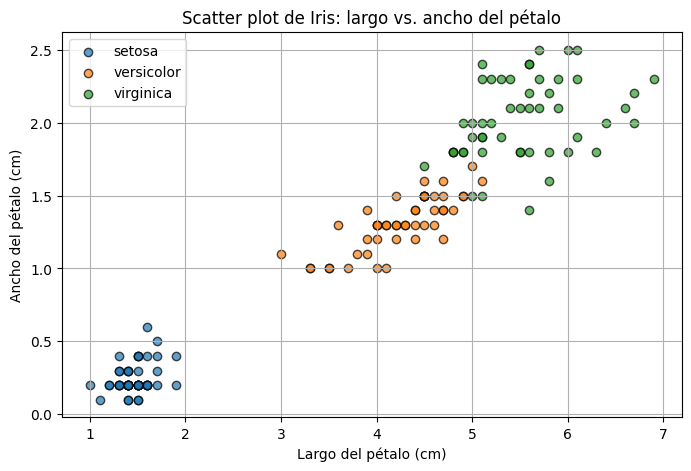

In [6]:
fig, ax = plt.subplots()  # Crea la figura (fig) y el área de dibujo (ax)
colores = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}  # Un color por especie
for especie, grupo in datos.groupby("especie"):  # Recorre cada especie con su subtabla
    ax.scatter(grupo["largo_petalo"], grupo["ancho_petalo"], label=especie, color=colores[especie], alpha=0.7, edgecolor="k")  # Dibuja los puntos
ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal
ax.set_ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje vertical
ax.set_title("Scatter plot de Iris: largo vs. ancho del pétalo")  # Título de la gráfica
ax.legend()  # Muestra la leyenda con las especies
plt.show()  # Muestra la gráfica en el notebook

**Interpretación.** *Setosa* (azul) forma un grupo completamente aparte de *versicolor* (naranja): se puede trazar una recta que las separe sin errores. Es el escenario ideal para el Perceptrón. *Versicolor* y *virginica* se acercan y se traslapan un poco; eso lo veremos en la sección de limitaciones.

### 3.4 Etapa 4: Preparación de los datos

Pasos de esta etapa:
1. **Seleccionar** solo las especies *setosa* y *versicolor*, porque el Perceptrón es un clasificador binario.
2. **Codificar** la especie como número: *setosa* = 0 y *versicolor* = 1.
3. **Separar** en entrenamiento (80 %) y prueba (20 %), manteniendo la proporción de clases (`stratify`).
4. **Estandarizar** las características. El escalador se ajusta **solo con los datos de entrenamiento** para no filtrar información del conjunto de prueba.

In [7]:
CARACTERISTICAS = ["largo_petalo", "ancho_petalo"]  # Las dos variables de entrada (X) que usaremos
binario = datos[datos["especie"].isin(["setosa", "versicolor"])].copy()  # Se queda solo con las dos especies elegidas
X = binario[CARACTERISTICAS].values  # Matriz de entradas (100 filas x 2 columnas) como arreglo NumPy
y = (binario["especie"] == "versicolor").astype(int).values  # Etiqueta: 1 si es versicolor, 0 si es setosa

print("Forma de X:", X.shape)  # Confirma el tamaño de la matriz de entradas
print("Clases en y (0 = setosa, 1 = versicolor):", np.bincount(y))  # Cuenta cuántas hay de cada clase

Forma de X: (100, 2)
Clases en y (0 = setosa, 1 = versicolor): [50 50]


In [8]:
X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos en entrenamiento y prueba
    X, y,  # Entradas y etiquetas que se van a dividir
    test_size=0.2,  # 20 % de las observaciones se reservan para prueba
    random_state=42,  # Semilla para que la división sea siempre la misma
    stratify=y  # Mantiene la misma proporción de clases en ambos conjuntos
)  # Cierra la llamada a train_test_split

print("Observaciones de entrenamiento:", X_train.shape[0])  # Cuántas filas quedaron para entrenar
print("Observaciones de prueba:", X_test.shape[0])  # Cuántas filas quedaron para probar
print("Clases en entrenamiento:", np.bincount(y_train))  # Balance de clases en entrenamiento
print("Clases en prueba:", np.bincount(y_test))  # Balance de clases en prueba

Observaciones de entrenamiento: 80
Observaciones de prueba: 20
Clases en entrenamiento: [40 40]
Clases en prueba: [10 10]


### 3.5 Etapa 5: Entrenamiento del modelo con scikit-learn

Armamos un `Pipeline` con dos pasos:
1. `StandardScaler()`: estandariza las características.
2. `Perceptron()`: aprende los pesos $\mathbf{w}$ y el sesgo $b$.

Parámetros del Perceptrón:
- `eta0=1.0`: tasa de aprendizaje $\eta$.
- `max_iter=1000`: máximo de épocas.
- `shuffle=False`: no reordena los datos en cada época (así podemos comparar con nuestra versión desde cero).
- `random_state=42`: reproducibilidad.

In [9]:
modelo = make_pipeline(  # Crea el pipeline del modelo
    StandardScaler(),  # Paso 1: estandariza cada característica (media 0, desviación 1)
    Perceptron(eta0=1.0, max_iter=1000, shuffle=False, random_state=42)  # Paso 2: el Perceptrón
)  # Cierra la creación del pipeline

modelo.fit(X_train, y_train)  # Entrena: ajusta el escalador y luego aprende los pesos corrigiendo errores por épocas

percep = modelo.named_steps["perceptron"]  # Extrae el Perceptrón ya entrenado del pipeline
escalador = modelo.named_steps["standardscaler"]  # Extrae el escalador ya ajustado del pipeline

print("Pesos aprendidos (w1, w2):", percep.coef_[0])  # Pesos de cada característica (en escala estandarizada)
print("Sesgo aprendido (b):", percep.intercept_[0])  # Sesgo del modelo
print("Épocas ejecutadas hasta detenerse:", percep.n_iter_)  # Pasadas completas por los datos, incluyendo 5 de espera sin mejora

Pesos aprendidos (w1, w2): [1.40250765 1.08271901]
Sesgo aprendido (b): 0.0
Épocas ejecutadas hasta detenerse: 7


**Interpretación.** Los pesos y el sesgo definen la recta $w_1x_1 + w_2x_2 + b = 0$ (en las variables ya estandarizadas). El modelo aprendió rápido porque los datos son linealmente separables, tal como predice el teorema de convergencia. Ojo con `n_iter_`: scikit-learn no se detiene en cuanto llega a cero errores, sino que espera 5 épocas más sin mejora (parámetro `n_iter_no_change=5`) para confirmar. Por eso reporta más épocas de las que el algoritmo realmente necesitó (lo vemos en la siguiente sección).

### 3.6 Etapa 6: Verificación, Perceptrón programado desde cero

Para comprobar que entendemos el algoritmo, implementamos **a mano** la regla de la sección 2.3 con NumPy y la comparamos con scikit-learn. Usamos los mismos datos estandarizados.

In [10]:
def perceptron_desde_cero(X_in, y_in, eta=1.0, epocas=100):  # Función que entrena un perceptrón siguiendo la regla de la sección 2.3
    y_pm = np.where(y_in == 1, 1, -1)  # Convierte las etiquetas 0/1 a -1/+1
    w = np.zeros(X_in.shape[1])  # Pesos iniciales: un cero por cada característica
    b = 0.0  # Sesgo inicial en cero
    errores_por_epoca = []  # Aquí guardaremos cuántos errores hubo en cada época
    for epoca in range(epocas):  # Repite el proceso por un máximo de "epocas" pasadas
        errores = 0  # Contador de errores de esta época
        for xi, yi in zip(X_in, y_pm):  # Recorre los ejemplos uno por uno con su etiqueta
            if yi * (np.dot(w, xi) + b) <= 0:  # Si y*z <= 0, el ejemplo está mal clasificado
                w = w + eta * yi * xi  # Corrige los pesos: w <- w + eta * y * x
                b = b + eta * yi  # Corrige el sesgo: b <- b + eta * y
                errores += 1  # Suma uno al contador de errores
        errores_por_epoca.append(errores)  # Guarda los errores de esta época
        if errores == 0:  # Si en toda la época no hubo errores...
            break  # ...el algoritmo convergió y se detiene
    return w, b, errores_por_epoca  # Devuelve pesos, sesgo y el historial de errores

X_train_esc = escalador.transform(X_train)  # Aplica el escalado (ajustado con entrenamiento) a los datos de entrenamiento
w_scratch, b_scratch, historial = perceptron_desde_cero(X_train_esc, y_train)  # Entrena nuestra versión casera

print("Pesos (desde cero):  ", w_scratch)  # Pesos de nuestra implementación
print("Pesos (scikit-learn):", percep.coef_[0])  # Pesos de scikit-learn
print("Sesgo (desde cero):  ", b_scratch)  # Sesgo de nuestra implementación
print("Sesgo (scikit-learn):", percep.intercept_[0])  # Sesgo de scikit-learn
print("¿Coinciden los pesos y el sesgo?", np.allclose(w_scratch, percep.coef_[0]) and np.isclose(b_scratch, percep.intercept_[0]))  # Compara ambos
print("Errores por época (desde cero):", historial)  # Cómo fueron bajando los errores hasta llegar a 0

Pesos (desde cero):   [1.40250765 1.08271901]
Pesos (scikit-learn): [1.40250765 1.08271901]
Sesgo (desde cero):   0.0
Sesgo (scikit-learn): 0.0
¿Coinciden los pesos y el sesgo? True
Errores por época (desde cero): [2, 0]


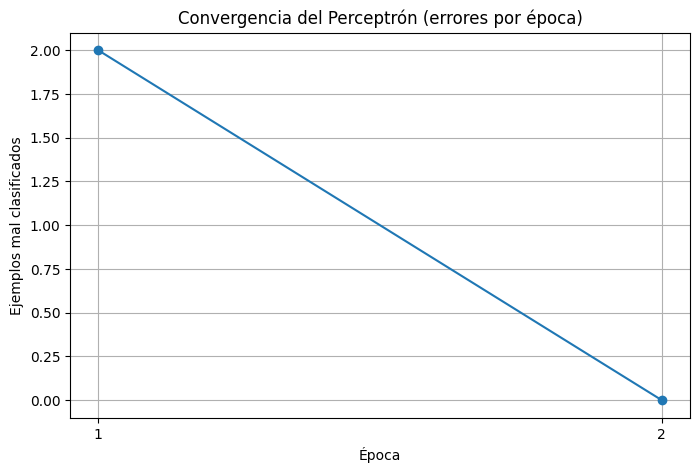

In [11]:
fig, ax = plt.subplots()  # Crea la figura y el área de dibujo
ax.plot(range(1, len(historial) + 1), historial, "o-")  # Errores de clasificación en cada época
ax.set_xlabel("Época")  # Etiqueta del eje horizontal
ax.set_ylabel("Ejemplos mal clasificados")  # Etiqueta del eje vertical
ax.set_title("Convergencia del Perceptrón (errores por época)")  # Título de la gráfica
ax.set_xticks(range(1, len(historial) + 1))  # Muestra solo números enteros de época en el eje
plt.show()  # Muestra la gráfica

**Interpretación.** En la primera época el perceptrón cometió 2 errores (y los corrigió); en la segunda ya no cometió ninguno, así que **convergió en 2 épocas**. Desde ese momento clasifica bien todo el conjunto de entrenamiento y deja de modificar sus pesos. Esa es la convergencia garantizada por el teorema para datos linealmente separables. Las 7 épocas que reportó scikit-learn son estas 2 más las 5 épocas de espera sin mejora. Como los pesos y el sesgo coinciden exactamente, confirmamos que entendemos el algoritmo.

### 3.7 Etapa 7: Evaluación del modelo (métricas)

En clasificación se evalúa con métricas basadas en la **matriz de confusión**. Llamamos "positivo" a la clase 1 (*versicolor*):

| | Predicho: 0 | Predicho: 1 |
|---|---|---|
| **Real: 0** | VN (verdadero negativo) | FP (falso positivo) |
| **Real: 1** | FN (falso negativo) | VP (verdadero positivo) |

| Métrica | Fórmula | Qué indica |
|---|---|---|
| Exactitud (*accuracy*) | $\frac{VP+VN}{VP+VN+FP+FN}$ | Proporción total de aciertos |
| Precisión | $\frac{VP}{VP+FP}$ | De los que predije como 1, cuántos lo eran |
| Recall (sensibilidad) | $\frac{VP}{VP+FN}$ | De los que realmente eran 1, cuántos detecté |
| F1 | $2\cdot\frac{Precisión\cdot Recall}{Precisión+Recall}$ | Balance entre precisión y recall |

In [12]:
y_pred_train = modelo.predict(X_train)  # Predicciones sobre los datos de entrenamiento
y_pred_test = modelo.predict(X_test)  # Predicciones sobre los datos de prueba (nunca vistos)

def calcular_metricas(y_real, y_est):  # Función que devuelve las métricas principales de un conjunto
    return {  # Devuelve un diccionario con las métricas
        "Exactitud": accuracy_score(y_real, y_est),  # Proporción de aciertos
        "Precisión": precision_score(y_real, y_est),  # Precisión de la clase positiva
        "Recall": recall_score(y_real, y_est),  # Sensibilidad de la clase positiva
        "F1": f1_score(y_real, y_est)  # Media armónica de precisión y recall
    }  # Cierra el diccionario

metricas = pd.DataFrame({  # Tabla comparando entrenamiento y prueba
    "Entrenamiento": calcular_metricas(y_train, y_pred_train),  # Métricas con los datos de entrenamiento
    "Prueba": calcular_metricas(y_test, y_pred_test)  # Métricas con los datos de prueba
})  # Cierra la creación de la tabla
metricas.round(4)  # Muestra la tabla con 4 decimales

,Entrenamiento,Prueba
Exactitud,1.0,1.0
Precisión,1.0,1.0
Recall,1.0,1.0
F1,1.0,1.0


Matriz de confusión (filas = real, columnas = predicho):
 [[10  0]
 [ 0 10]]


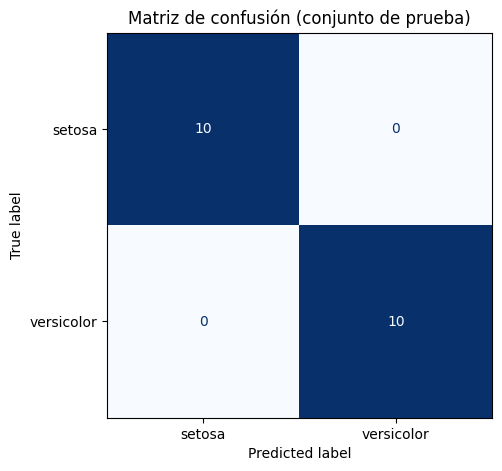

In [13]:
cm = confusion_matrix(y_test, y_pred_test)  # Calcula la matriz de confusión con los datos de prueba
print("Matriz de confusión (filas = real, columnas = predicho):\n", cm)  # La imprime en texto

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["setosa", "versicolor"])  # Prepara la gráfica de la matriz
disp.plot(cmap="Blues", colorbar=False)  # La dibuja en azules y sin barra de color
plt.title("Matriz de confusión (conjunto de prueba)")  # Título de la gráfica
plt.grid(False)  # Quita la cuadrícula para que se vea limpia
plt.show()  # Muestra la gráfica

In [14]:
print("Reporte de clasificación (prueba):\n")  # Título del reporte
print(classification_report(y_test, y_pred_test, target_names=["setosa", "versicolor"]))  # Precisión, recall y F1 por clase

cv = cross_val_score(modelo, X_train, y_train, cv=5, scoring="accuracy")  # Exactitud con validación cruzada de 5 pliegues
print("Exactitud en validación cruzada (5 pliegues):", cv.round(3))  # Resultado de cada pliegue
print(f"Promedio: {cv.mean():.4f}  |  Desviación: {cv.std():.4f}")  # Promedio y variación entre pliegues

Reporte de clasificación (prueba):

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



Exactitud en validación cruzada (5 pliegues): [1. 1. 1. 1. 1.]
Promedio: 1.0000  |  Desviación: 0.0000


**Interpretación.** Todas las métricas salen perfectas (1.0), incluso en validación cruzada. Esto **no significa que el Perceptrón sea mágico**: significa que *setosa* y *versicolor* son linealmente separables con las medidas del pétalo, justo el caso para el que sirve el algoritmo. Con datos reales más "sucios" esperaríamos métricas menores (lo comprobamos en la sección 3.10).

### 3.8 Etapa 8: Visualización de la frontera de decisión

Dibujamos la región que el modelo asigna a cada clase y la recta $w_1x_1+w_2x_2+b=0$ sobre los puntos de entrenamiento y prueba. Evaluamos el modelo sobre una malla de puntos que cubre todo el plano.

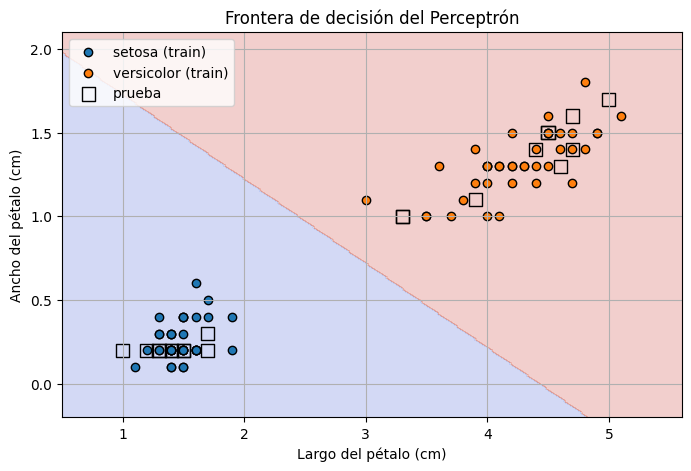

In [15]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5  # Rango horizontal de la malla, con un margen
y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3  # Rango vertical de la malla, con un margen
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))  # Malla de 300 x 300 puntos
puntos_malla = np.c_[xx.ravel(), yy.ravel()]  # Convierte la malla en una lista de pares (x, y)
zz = modelo.predict(puntos_malla).reshape(xx.shape)  # Predice la clase de cada punto y la devuelve a forma de malla

fig, ax = plt.subplots()  # Crea la figura y el área de dibujo
ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")  # Colorea las regiones de decisión de cada clase
ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color="tab:blue", edgecolor="k", label="setosa (train)")  # Setosa, entrenamiento
ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color="tab:orange", edgecolor="k", label="versicolor (train)")  # Versicolor, entrenamiento
ax.scatter(X_test[:, 0], X_test[:, 1], marker="s", facecolor="none", edgecolor="black", s=90, label="prueba")  # Prueba, cuadros vacíos
ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal
ax.set_ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje vertical
ax.set_title("Frontera de decisión del Perceptrón")  # Título de la gráfica
ax.legend()  # Muestra la leyenda
plt.show()  # Muestra la gráfica

**Interpretación.** La frontera entre las dos regiones coloreadas es una **línea recta**, como corresponde a un clasificador lineal. Todos los puntos de *setosa* quedan de un lado y todos los de *versicolor* del otro.

### 3.9 Etapa 9: Predicción con datos nuevos

Clasificamos flores nuevas que no estaban en el dataset. El pipeline aplica el escalado automáticamente antes de predecir.

In [16]:
flores_nuevas = np.array([[1.4, 0.2], [4.5, 1.4], [1.6, 0.4], [4.0, 1.2]])  # 4 flores: [largo_petalo, ancho_petalo] en cm
clases_pred = modelo.predict(flores_nuevas)  # El modelo predice 0 (setosa) o 1 (versicolor) para cada flor
nombres = np.where(clases_pred == 1, "versicolor", "setosa")  # Convierte 0/1 a los nombres de la especie

resultado = pd.DataFrame({  # Tabla con las entradas y la predicción
    "largo_petalo": flores_nuevas[:, 0],  # Primera característica de cada flor nueva
    "ancho_petalo": flores_nuevas[:, 1],  # Segunda característica de cada flor nueva
    "predicción": nombres  # Especie predicha por el modelo
})  # Cierra la creación de la tabla
resultado  # Muestra la tabla

,largo_petalo,ancho_petalo,predicción
0,1.4,0.2,setosa
1,4.5,1.4,versicolor
2,1.6,0.4,setosa
3,4.0,1.2,versicolor


### 3.10 Etapa 10: Limitaciones del Perceptrón

#### Caso A: clases que se traslapan (*versicolor* vs. *virginica*)
Repetimos el proceso con dos especies que **no** son perfectamente separables con una recta.

In [17]:
dificil = datos[datos["especie"].isin(["versicolor", "virginica"])].copy()  # Se queda con versicolor y virginica
Xd = dificil[CARACTERISTICAS].values  # Matriz de entradas de este caso
yd = (dificil["especie"] == "virginica").astype(int).values  # Etiqueta: 1 si es virginica, 0 si es versicolor
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42, stratify=yd)  # Divide train/test

modelo_d = make_pipeline(StandardScaler(), Perceptron(eta0=1.0, max_iter=1000, random_state=42))  # Mismo tipo de pipeline
modelo_d.fit(Xd_tr, yd_tr)  # Entrena con los datos de este caso

print(f"Exactitud en entrenamiento: {accuracy_score(yd_tr, modelo_d.predict(Xd_tr)):.4f}")  # Aciertos en entrenamiento
print(f"Exactitud en prueba:        {accuracy_score(yd_te, modelo_d.predict(Xd_te)):.4f}")  # Aciertos en prueba
print("Épocas ejecutadas:", modelo_d.named_steps["perceptron"].n_iter_)  # Épocas usadas hasta que el entrenamiento se detuvo

Exactitud en entrenamiento: 0.9750
Exactitud en prueba:        0.8500
Épocas ejecutadas: 8


**Interpretación.** Cuando las clases se traslapan, el Perceptrón **no puede llegar a cero errores**: siempre queda algún punto del lado equivocado de la recta. Aquí la exactitud en entrenamiento no es 1.0 y la de prueba baja a 0.85, claramente peor que en el caso *setosa* vs. *versicolor*. El entrenamiento se detuvo por el criterio de tolerancia (la pérdida dejó de mejorar), no porque haya logrado clasificar todo bien. Además, el resultado de un perceptrón en datos no separables es inestable: depende del orden de los datos y de la división train/test.

#### Caso B: el problema XOR
El XOR es el ejemplo clásico de un problema que **ningún** clasificador lineal puede resolver: los puntos (0,0) y (1,1) son de una clase y (0,1) y (1,0) de la otra.

In [18]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])  # Las 4 combinaciones posibles de dos entradas binarias
y_xor = np.array([0, 1, 1, 0])  # Salida del XOR: 1 solo cuando las entradas son distintas

p_xor = Perceptron(eta0=1.0, max_iter=1000, tol=None, random_state=42)  # Perceptrón que usa las 1000 épocas completas
p_xor.fit(X_xor, y_xor)  # Intenta aprender el XOR

print("Predicciones:", p_xor.predict(X_xor))  # Lo que predice el modelo para las 4 combinaciones
print("Valores reales:", y_xor)  # Lo que debería predecir
print("Exactitud:", accuracy_score(y_xor, p_xor.predict(X_xor)))  # Siempre queda en 0.75 o menos: no existe recta que lo separe

Predicciones: [0 0 0 0]
Valores reales: [0 1 1 0]
Exactitud: 0.5


**Interpretación.** El Perceptrón nunca clasifica bien los 4 puntos del XOR, porque no existe ninguna recta que separe esas dos clases. La solución histórica fue añadir **capas ocultas**, que es el **Perceptrón multicapa** (`MLPClassifier` en scikit-learn).

## 4. Conclusiones

1. El **Perceptrón** es un clasificador binario lineal: calcula $z=\mathbf{w}^T\mathbf{x}+b$ y aplica una función escalón para decidir la clase.
2. Aprende **corrigiendo sus errores**: solo actualiza $\mathbf{w}$ y $b$ cuando clasifica mal un ejemplo, con la regla $\mathbf{w}\leftarrow\mathbf{w}+\eta\,y\,\mathbf{x}$.
3. Si los datos son **linealmente separables**, el algoritmo converge en un número finito de pasos (lo vimos al llegar a 0 errores por época). Nuestra implementación desde cero coincide con la de scikit-learn.
4. Los datos se importaron desde un **CSV** y pasaron por todo el pipeline: descripción, scatter plot, separación train/test, escalado, entrenamiento y evaluación.
5. Se evalúa con **exactitud, precisión, recall, F1 y matriz de confusión**, y siempre con datos que el modelo no vio.
6. Sus **limitaciones** (datos no separables, XOR) motivan modelos más potentes como el Perceptrón multicapa y las redes neuronales profundas.

### Referencias
- scikit-learn, *Perceptron*: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html
- scikit-learn, *Dataset Iris*: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- Rosenblatt, F. (1958). *The perceptron: a probabilistic model for information storage and organization in the brain*. Psychological Review, 65(6).